# Hyperparameter Optimization and Model Comparison

## 1. Objective

This notebook optimizes the regression models across **every combination of algorithm and feature set** evaluated in `07_feature_integration.ipynb`.

The experiment grid has **16 configurations**: 4 algorithms × 4 feature sets.

| | Baseline (8) | Amenities (257) | Geospatial (48) | Combined (297) |
|---|:---:|:---:|:---:|:---:|
| **Linear Regression** (tuned as Ridge) | ✔ | ✔ | ✔ | ✔ |
| **Decision Tree** | ✔ | ✔ | ✔ | ✔ |
| **Random Forest** | ✔ | ✔ | ✔ | ✔ |
| **Gradient Boosting** (Histogram-based) | ✔ | ✔ | ✔ | ✔ |

Each of the 16 cells is tuned independently, so the final comparison answers two questions on equal footing:

1. Does hyperparameter tuning improve each model relative to the untuned results of Notebook 07?
2. After tuning, which feature set is best for each algorithm, and which algorithm / feature-set pair is best overall?

**Methodology**
- Preserve the original group-aware train-validation-test split based on `uru_id`.
- Use `GroupKFold` cross-validation on the training partition only.
- Optimize **MAE** (`neg_mean_absolute_error`) because MAE is the primary comparison metric.
- Use `RandomizedSearchCV` with compact, model-specific search spaces. The **same search space and the same budget** (`N_ITER`, or `N_ITER_BY_MODEL` for Random Forest) are used for every feature set, so differences between feature sets are not caused by different tuning effort.
- Select hyperparameters using cross-validation, then evaluate each of the 16 tuned models once on validation.
- Select the final configuration (algorithm + feature set) using validation MAE, and evaluate **only that configuration** on the test set.

> Runtime note: 16 searches are run, each with `N_ITER × N_SPLITS` model fits on a large dataset. Random Forest on the Amenities and Combined sets will dominate the runtime. Fitted searches are cached to disk (see `USE_CACHE`), so an interrupted run resumes where it stopped instead of starting over.

## 2. Imports and configuration

In [ ]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import loguniform, randint

SEED = 710
N_ITER = 10          # random configurations sampled per (model, feature set)
N_SPLITS = 3         # GroupKFold splits
N_ITER_BY_MODEL = {"Random Forest": 5}   # smaller budget for the slowest model; others use N_ITER
USE_CACHE = True     # reuse fitted searches saved on disk

DATA_DIR = Path("../../data/processed")
OUTPUT_DIR = Path("../../output/models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_DATA_PATH = DATA_DIR / "chicago_prepared_full.csv"
AMENITIES_PATH = DATA_DIR / "chicago_amenity_features.csv"
GEOSPATIAL_PATH = DATA_DIR / "geospatial_features.csv"

for path in [BASELINE_DATA_PATH, AMENITIES_PATH, GEOSPATIAL_PATH]:
    assert path.exists(), f"File not found: {path.resolve()}"

# The 16-cell experiment grid
MODEL_ORDER = ["Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]
FEATURE_SET_ORDER = ["Baseline", "Amenities", "Geospatial", "Combined"]

# Same palette as Notebook 07
feature_colors = {
    "Baseline": "#66788A",
    "Amenities": "#8CA9A0",
    "Geospatial": "#C5A27D",
    "Combined": "#847DA3"
}

print(f"Experiment grid: {len(MODEL_ORDER)} models x {len(FEATURE_SET_ORDER)} feature sets "
      f"= {len(MODEL_ORDER) * len(FEATURE_SET_ORDER)} searches")
print(f"Each search: {N_ITER} candidates x {N_SPLITS} folds (Random Forest: "
      f"{N_ITER_BY_MODEL.get('Random Forest', N_ITER)} candidates), + 1 refit")

Experiment grid: 4 models x 4 feature sets = 16 searches
Each search: 10 candidates x 3 folds (Random Forest: 5 candidates), + 1 refit


## 3. Load data and reproduce the original split

The split is recreated with the same seed and two-stage `GroupShuffleSplit` strategy used in the feature-integration notebook. This keeps rental units (`uru_id`) separated across train, validation, and test, and guarantees that all 16 configurations are trained and evaluated on exactly the same observations.

In [2]:
df = pd.read_csv(BASELINE_DATA_PATH)
df_amenities = pd.read_csv(AMENITIES_PATH)
df_geo = pd.read_csv(GEOSPATIAL_PATH)

# Baseline predictors from Notebook 05 / 07
numerical_features = [
    "bedrooms", "full_baths", "square_feet",
    "year_built", "listing_year", "listing_month"
]
categorical_features = ["address_zip", "uru_type"]
baseline_features = numerical_features + categorical_features

# Recreate the exact group-aware split
X_base = df[baseline_features].copy()
y = df["rent_amount"].copy()
groups = df["uru_id"].copy()

test_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(test_splitter.split(X_base, y, groups=groups))

X_dev = X_base.iloc[dev_idx].copy()
y_dev = y.iloc[dev_idx].copy()
groups_dev = groups.iloc[dev_idx].copy()

X_test_base = X_base.iloc[test_idx].copy()

val_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, val_idx = next(
    val_splitter.split(X_dev, y_dev, groups=groups_dev)
)

train_index = X_dev.index[train_idx]
val_index = X_dev.index[val_idx]
test_index = X_test_base.index

y_train = y.loc[train_index].copy()
y_val = y.loc[val_index].copy()
y_test = y.loc[test_index].copy()
groups_train = groups.loc[train_index].copy()

print("Train:", len(train_index), "| Validation:", len(val_index), "| Test:", len(test_index))
print("Unique training groups:", groups_train.nunique())

Train: 348494 | Validation: 87942 | Test: 108876
Unique training groups: 97428


## 4. Build the four feature sets

All amenity and geospatial predictors are merged once into a single wide table, using the same keys and feature definitions as Notebook 07. Each feature set is then defined as a subset of columns:

| Feature set | Composition |
|---|---|
| **Baseline** | 8 baseline predictors |
| **Amenities** | Baseline + non-constant amenity indicators |
| **Geospatial** | Baseline + geospatial proximity features |
| **Combined** | Baseline + amenities + geospatial |

Constant amenity indicators are identified using the training partition only. The row order of the original dataset is preserved, and the train, validation, and test indices are identical for all feature sets.

In [3]:
# Merge amenities
df_enriched = df.merge(
    df_amenities, on="listing_id", how="left",
    validate="one_to_one", sort=False
)
amenity_cols = [c for c in df_amenities.columns if c != "listing_id"]

# Exclude constant amenity columns based on training data only
train_amenities = df_enriched.loc[train_index, amenity_cols]
amenity_nunique = train_amenities.nunique(dropna=False)
selected_amenities = amenity_nunique[amenity_nunique > 1].index.tolist()

# Merge geospatial predictors
geo_keys = ["dwellsy_address_id", "address_city", "latitude", "longitude"]
geo_features = [c for c in df_geo.columns if c not in geo_keys]

df_geo_enriched = df.merge(
    df_geo, on=geo_keys, how="left",
    validate="many_to_one", sort=False
)

# Combine without changing the original row order
df_combined = df_enriched.copy()
for col in geo_features:
    df_combined[col] = df_geo_enriched[col].to_numpy()

# Define the four feature sets
feature_sets = {
    "Baseline":   {"amenities": [],                   "geo": []},
    "Amenities":  {"amenities": selected_amenities,   "geo": []},
    "Geospatial": {"amenities": [],                   "geo": geo_features},
    "Combined":   {"amenities": selected_amenities,   "geo": geo_features},
}

for cfg in feature_sets.values():
    cfg["features"] = baseline_features + cfg["amenities"] + cfg["geo"]
    assert len(cfg["features"]) == len(set(cfg["features"])), "Duplicate feature names detected."

assert list(feature_sets) == FEATURE_SET_ORDER

# Single wide matrix; each experiment selects its own columns
all_features = feature_sets["Combined"]["features"]
X_all = df_combined[all_features]

X_train_all = X_all.loc[train_index]
X_val_all = X_all.loc[val_index]
X_test_all = X_all.loc[test_index]

assert X_train_all.index.equals(y_train.index)
assert X_val_all.index.equals(y_val.index)
assert X_test_all.index.equals(y_test.index)

summary_rows = [
    {
        "Feature Set": name,
        "Baseline": len(baseline_features),
        "Amenities": len(cfg["amenities"]),
        "Geospatial": len(cfg["geo"]),
        "Total predictors": len(cfg["features"])
    }
    for name, cfg in feature_sets.items()
]
display(pd.DataFrame(summary_rows).set_index("Feature Set"))
print("Train / validation / test rows:", X_train_all.shape[0], X_val_all.shape[0], X_test_all.shape[0])

,Baseline,Amenities,Geospatial,Total predictors
Feature Set,,,,
Baseline,8,0,0,8
Amenities,8,249,0,257
Geospatial,8,0,40,48
Combined,8,249,40,297


Train / validation / test rows: 348494 87942 108876


## 5. Preprocessing pipelines

Two preprocessors are built for each feature set, reproducing the strategies of Notebook 07:

- **One-Hot preprocessor** (Ridge, Decision Tree, Random Forest): median imputation for numerical and geospatial variables; most-frequent imputation plus One-Hot Encoding for the two categorical variables; binary amenity indicators passed through unchanged.
- **Ordinal preprocessor** (Histogram Gradient Boosting): median imputation for numerical variables; most-frequent imputation, frequent-category grouping, and Ordinal Encoding for the two categorical variables; amenities passed through; geospatial columns median-imputed.

Because the amenity and geospatial blocks are optional, the builder only adds a transformer when its column list is non-empty. The two categorical columns always occupy positions 6 and 7 after transformation, so the categorical positions for Gradient Boosting are the same for all feature sets.

All preprocessing lives inside the model pipelines, so imputers and encoders are fitted separately within each cross-validation fold.

In [4]:
class FrequentCategoryGrouper(BaseEstimator, TransformerMixin):
    def __init__(self, max_categories=200):
        self.max_categories = max_categories

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.frequent_categories_ = [
            set(X.iloc[:, i].value_counts().head(self.max_categories).index)
            for i in range(X.shape[1])
        ]
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for i, frequent in enumerate(self.frequent_categories_):
            X.iloc[:, i] = X.iloc[:, i].where(X.iloc[:, i].isin(frequent), "__OTHER__")
        return X.to_numpy()


def to_string(X):
    # Named function (instead of a lambda) so fitted pipelines can be pickled and cached
    return X.astype(str)


def build_categorical_gb():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("to_string", FunctionTransformer(to_string)),
        ("grouper", FrequentCategoryGrouper(max_categories=200)),
        ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    ])


def build_preprocessors(amenity_features, geo_cols):
    # One-Hot preprocessor: Ridge, Decision Tree, Random Forest
    ohe_transformers = [
        ("num", SimpleImputer(strategy="median"), numerical_features + geo_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features),
    ]
    if amenity_features:
        ohe_transformers.append(("amenities", "passthrough", amenity_features))
    preprocessor_ohe = ColumnTransformer(ohe_transformers, remainder="drop")

    # Ordinal preprocessor: Histogram Gradient Boosting
    hgb_transformers = [
        ("num", SimpleImputer(strategy="median"), numerical_features),
        ("cat", build_categorical_gb(), categorical_features),
    ]
    if amenity_features:
        hgb_transformers.append(("amenities", "passthrough", amenity_features))
    if geo_cols:
        hgb_transformers.append(("geo", SimpleImputer(strategy="median"), geo_cols))
    preprocessor_hgb = ColumnTransformer(hgb_transformers, remainder="drop")

    return preprocessor_ohe, preprocessor_hgb


# Categorical positions after transformation (six numerical + two categorical first)
categorical_indices_hgb = [len(numerical_features), len(numerical_features) + 1]
print("HGB categorical feature positions:", categorical_indices_hgb)

HGB categorical feature positions: [6, 7]


## 6. Cross-validation and search spaces

`GroupKFold` ensures that observations belonging to the same `uru_id` remain in the same fold. The optimization objective is mean cross-validated MAE.

`Ridge` is used for the linear family because ordinary least squares has no hyperparameter to tune; its regularization strength (`alpha`) controls coefficient shrinkage. In all result tables this model appears as **Linear Regression** so it lines up with Notebook 07.

The search spaces are **identical for every feature set**. This keeps the tuning effort constant across columns of the comparison, so any difference between feature sets reflects the information they contain and not the search.

In [5]:
cv = GroupKFold(n_splits=N_SPLITS)

# Estimator actually fitted for each model label
tuned_estimator_name = {
    "Linear Regression": "Ridge",
    "Decision Tree": "DecisionTreeRegressor",
    "Random Forest": "RandomForestRegressor",
    "Gradient Boosting": "HistGradientBoostingRegressor"
}

def build_search_spaces(preprocessor_ohe, preprocessor_hgb):
    return {
        "Linear Regression": {
            "pipeline": Pipeline([
                ("preprocessor", preprocessor_ohe),
                ("model", Ridge())
            ]),
            "params": {
                "model__alpha": loguniform(1e-3, 1e3),
                "model__fit_intercept": [True, False]
            }
        },
        "Decision Tree": {
            "pipeline": Pipeline([
                ("preprocessor", preprocessor_ohe),
                ("model", DecisionTreeRegressor(random_state=SEED))
            ]),
            "params": {
                "model__max_depth": [None, 8, 12, 16, 20, 25, 30],
                "model__min_samples_split": randint(2, 30),
                "model__min_samples_leaf": randint(1, 20),
                "model__max_features": [None, "sqrt", 0.7]
            }
        },
        "Random Forest": {
            "pipeline": Pipeline([
                ("preprocessor", preprocessor_ohe),
                ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1))
            ]),
            "params": {
                # Bounded space: unrestricted depth + 1-sample leaves + 500 trees
                # is prohibitively slow on ~350k rows, repeated for 4 feature sets
                "model__n_estimators": randint(100, 251),
                "model__max_depth": [12, 16, 20, 25],
                "model__min_samples_split": randint(2, 20),
                "model__min_samples_leaf": randint(3, 15),
                "model__max_features": [0.5, 0.7, 1.0]
            }
        },
        "Gradient Boosting": {
            "pipeline": Pipeline([
                ("preprocessor", preprocessor_hgb),
                ("model", HistGradientBoostingRegressor(
                    random_state=SEED,
                    categorical_features=categorical_indices_hgb
                ))
            ]),
            "params": {
                "model__learning_rate": loguniform(0.02, 0.2),
                "model__max_iter": randint(150, 601),
                "model__max_leaf_nodes": randint(15, 64),
                "model__min_samples_leaf": randint(10, 80),
                "model__l2_regularization": loguniform(1e-4, 10)
            }
        }
    }

## 7. Run hyperparameter optimization (16 searches)

The loop iterates over **feature sets** (outer) and **models** (inner). Each search is fitted on the training partition only, passing `groups_train` to the cross-validation splitter. The validation and test targets are never used to select hyperparameters.

`n_jobs=1` is used at the search level to avoid launching several large model fits simultaneously; Random Forest itself can use all available cores.

When `USE_CACHE=True`, every finished search is saved to `CACHE_DIR`. Re-running the cell loads finished searches from disk and only fits the missing ones. The cache key includes `N_ITER`, `N_SPLITS`, and `SEED`; delete the cache folder (or set `USE_CACHE=False`) to force a fresh run.

In [6]:
searches = {}   # (feature_set, model) -> dict with estimator, CV summary, and cv_results
total_runs = len(FEATURE_SET_ORDER) * len(MODEL_ORDER)
run_number = 0

for fs_name in FEATURE_SET_ORDER:
    cfg = feature_sets[fs_name]
    preprocessor_ohe, preprocessor_hgb = build_preprocessors(cfg["amenities"], cfg["geo"])
    spaces = build_search_spaces(preprocessor_ohe, preprocessor_hgb)
    X_train_fs = X_train_all[cfg["features"]]

    for model_name in MODEL_ORDER:
        run_number += 1
        n_iter = N_ITER_BY_MODEL.get(model_name, N_ITER)
        cache_file = CACHE_DIR / (
            f"{fs_name}__{model_name.replace(' ', '_')}"
            f"__n{n_iter}_k{N_SPLITS}_s{SEED}.joblib"
        )

        if USE_CACHE and cache_file.exists():
            searches[(fs_name, model_name)] = joblib.load(cache_file)
            record = searches[(fs_name, model_name)]
            print(f"[{run_number:>2}/{total_runs}] {fs_name} | {model_name}: "
                  f"loaded from cache (CV MAE = {record['cv_mae']:.2f})")
            continue

        print(f"\n[{run_number:>2}/{total_runs}] Optimizing: {model_name} on {fs_name} "
              f"({len(cfg['features'])} predictors)")
        start = time.time()

        search = RandomizedSearchCV(
            estimator=spaces[model_name]["pipeline"],
            param_distributions=spaces[model_name]["params"],
            n_iter=n_iter,
            scoring="neg_mean_absolute_error",
            cv=cv,
            refit=True,
            random_state=SEED,
            n_jobs=1,
            verbose=1,
            return_train_score=True
        )
        search.fit(X_train_fs, y_train, groups=groups_train)
        elapsed_min = (time.time() - start) / 60

        record = {
            "estimator": search.best_estimator_,
            "cv_mae": -search.best_score_,
            "cv_std": search.cv_results_["std_test_score"][search.best_index_],
            "best_params": search.best_params_,
            "minutes": elapsed_min,
            "cv_results": pd.DataFrame(search.cv_results_)
        }
        searches[(fs_name, model_name)] = record

        if USE_CACHE:
            joblib.dump(record, cache_file)

        print(f"    Best CV MAE: {record['cv_mae']:.2f} | "
              f"Time: {elapsed_min:.1f} min")
        print(f"    Best parameters: {record['best_params']}")

print("\nAll searches finished:", len(searches), "of", total_runs)

[ 1/16] Baseline | Linear Regression: loaded from cache (CV MAE = 363.27)
[ 2/16] Baseline | Decision Tree: loaded from cache (CV MAE = 249.95)

[ 3/16] Optimizing: Random Forest on Baseline (8 predictors)
Fitting 3 folds for each of 5 candidates, totalling 15 fits
    Best CV MAE: 265.93 | Time: 19.1 min
    Best parameters: {'model__max_depth': 25, 'model__max_features': 1.0, 'model__min_samples_leaf': 10, 'model__min_samples_split': 8, 'model__n_estimators': 183}

[ 4/16] Optimizing: Gradient Boosting on Baseline (8 predictors)
Fitting 3 folds for each of 10 candidates, totalling 30 fits
    Best CV MAE: 220.57 | Time: 3.0 min
    Best parameters: {'model__l2_regularization': np.float64(0.0019513910359888207), 'model__learning_rate': np.float64(0.1098817199798199), 'model__max_iter': 475, 'model__max_leaf_nodes': 47, 'model__min_samples_leaf': 55}

[ 5/16] Optimizing: Linear Regression on Amenities (257 predictors)
Fitting 3 folds for each of 10 candidates, totalling 30 fits
    Bes

/opt/anaconda3/envs/pricing-accolade/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.074982975153506e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/opt/anaconda3/envs/pricing-accolade/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.1199114317714303e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/opt/anaconda3/envs/pricing-accolade/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.156208192014875e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/opt/anaconda3/envs/pricing-accolade/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.654388698320797e-16.
  return linalg.solv

    Best CV MAE: 304.85 | Time: 1.2 min
    Best parameters: {'model__alpha': np.float64(27.502534549448693), 'model__fit_intercept': True}

[14/16] Optimizing: Decision Tree on Combined (297 predictors)
Fitting 3 folds for each of 10 candidates, totalling 30 fits
    Best CV MAE: 233.53 | Time: 3.6 min
    Best parameters: {'model__max_depth': 25, 'model__max_features': None, 'model__min_samples_leaf': 6, 'model__min_samples_split': 2}

[15/16] Optimizing: Random Forest on Combined (297 predictors)
Fitting 3 folds for each of 5 candidates, totalling 15 fits
    Best CV MAE: 184.11 | Time: 54.4 min
    Best parameters: {'model__max_depth': 20, 'model__max_features': 0.5, 'model__min_samples_leaf': 4, 'model__min_samples_split': 11, 'model__n_estimators': 206}

[16/16] Optimizing: Gradient Boosting on Combined (297 predictors)
Fitting 3 folds for each of 10 candidates, totalling 30 fits
    Best CV MAE: 184.14 | Time: 21.5 min
    Best parameters: {'model__l2_regularization': np.float64

## 8. Cross-validation results

The table below reports the best mean CV MAE found for each of the 16 configurations, computed on the **training partition only**. This is the criterion used to choose hyperparameters within each cell; it is not the final comparison.

In [7]:
cv_rows = []
for (fs_name, model_name), rec in searches.items():
    cv_rows.append({
        "Feature Set": fs_name,
        "Model": model_name,
        "Estimator": tuned_estimator_name[model_name],
        "Predictors": len(feature_sets[fs_name]["features"]),
        "CV MAE": rec["cv_mae"],
        "CV Std. MAE": rec["cv_std"],
        "Search time (min)": rec["minutes"],
        "Best Parameters": rec["best_params"]
    })

optimization_summary = pd.DataFrame(cv_rows)

def metric_matrix(frame, value_col):
    # Model x Feature Set matrix in the same layout as Notebook 07
    return (
        frame.pivot(index="Model", columns="Feature Set", values=value_col)
        .loc[MODEL_ORDER, FEATURE_SET_ORDER]
    )

print("Best cross-validation MAE (training partition only):")
display(metric_matrix(optimization_summary, "CV MAE").round(2))

print("\nBest hyperparameters per configuration:")
with pd.option_context("display.max_colwidth", None):
    display(
        optimization_summary
        .sort_values(["Model", "Feature Set"], key=lambda s: s.map(
            {**{m: i for i, m in enumerate(MODEL_ORDER)},
             **{f: i for i, f in enumerate(FEATURE_SET_ORDER)}}
        ))
        [["Model", "Feature Set", "CV MAE", "CV Std. MAE", "Search time (min)", "Best Parameters"]]
        .round(3)
        .reset_index(drop=True)
    )

Best cross-validation MAE (training partition only):


Feature Set,Baseline,Amenities,Geospatial,Combined
Model,,,,
Linear Regression,363.27,308.48,369.11,304.85
Decision Tree,249.95,250.10,230.80,233.53
Random Forest,265.93,226.24,188.68,184.11
Gradient Boosting,220.57,197.28,191.87,184.14



Best hyperparameters per configuration:


,Model,Feature Set,CV MAE,CV Std. MAE,Search time (min),Best Parameters
0,Linear Regression,Baseline,363.272,2.140,0.173,"{'model__alpha': 27.502534549448693, 'model__fit_intercept': True}"
1,Linear Regression,Amenities,308.479,1.841,0.808,"{'model__alpha': 27.502534549448693, 'model__fit_intercept': True}"
2,Linear Regression,Geospatial,369.111,3.439,1.092,"{'model__alpha': 0.003375477234864907, 'model__fit_intercept': True}"
3,Linear Regression,Combined,304.851,2.618,1.174,"{'model__alpha': 27.502534549448693, 'model__fit_intercept': True}"
4,Decision Tree,Baseline,249.946,3.829,1.508,"{'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__min_samples_split': 28}"
5,Decision Tree,Amenities,250.101,4.559,2.831,"{'model__max_depth': None, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 26}"
6,Decision Tree,Geospatial,230.802,2.871,12.890,"{'model__max_depth': 25, 'model__max_features': None, 'model__min_samples_leaf': 6, 'model__min_samples_split': 2}"
7,Decision Tree,Combined,233.527,3.797,3.580,"{'model__max_depth': 25, 'model__max_features': None, 'model__min_samples_leaf': 6, 'model__min_samples_split': 2}"
8,Random Forest,Baseline,265.926,3.106,19.113,"{'model__max_depth': 25, 'model__max_features': 1.0, 'model__min_samples_leaf': 10, 'model__min_samples_split': 8, 'model__n_estimators': 183}"
9,Random Forest,Amenities,226.238,2.436,52.582,"{'model__max_depth': 25, 'model__max_features': 1.0, 'model__min_samples_leaf': 10, 'model__min_samples_split': 8, 'model__n_estimators': 183}"


In [19]:
def clean_value(value):
    # Show numpy scalars as plain numbers with sensible precision
    if isinstance(value, (float, np.floating)):
        return float(f"{value:.4g}")
    if isinstance(value, np.integer):
        return int(value)
    return value

print("Best hyperparameters per configuration (one table per model):")
for model_name in MODEL_ORDER:
    rows = []
    for fs_name in FEATURE_SET_ORDER:
        rec = searches[(fs_name, model_name)]
        params = {key.replace("model__", ""): clean_value(value)
                  for key, value in rec["best_params"].items()}
        rows.append({
            "Feature Set": fs_name,
            "CV MAE": round(rec["cv_mae"], 2),
            "CV Std. MAE": round(rec["cv_std"], 2),
            "Search time (min)": round(rec["minutes"], 1),
            **params
        })

    print(f"\n{model_name} (fitted as {tuned_estimator_name[model_name]})")
    display(pd.DataFrame(rows, dtype=object).set_index("Feature Set"))

Best hyperparameters per configuration (one table per model):

Linear Regression (fitted as Ridge)


,CV MAE,CV Std. MAE,Search time (min),alpha,fit_intercept
Feature Set,,,,,
Baseline,363.27,2.14,0.2,27.5,True
Amenities,308.48,1.84,0.8,27.5,True
Geospatial,369.11,3.44,1.1,0.003375,True
Combined,304.85,2.62,1.2,27.5,True



Decision Tree (fitted as DecisionTreeRegressor)


,CV MAE,CV Std. MAE,Search time (min),max_depth,max_features,min_samples_leaf,min_samples_split
Feature Set,,,,,,,
Baseline,249.95,3.83,1.5,None,0.7,1,28
Amenities,250.1,4.56,2.8,None,None,1,26
Geospatial,230.8,2.87,12.9,25,None,6,2
Combined,233.53,3.8,3.6,25,None,6,2



Random Forest (fitted as RandomForestRegressor)


,CV MAE,CV Std. MAE,Search time (min),max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
Feature Set,,,,,,,,
Baseline,265.93,3.11,19.1,25,1.0,10,8,183
Amenities,226.24,2.44,52.6,25,1.0,10,8,183
Geospatial,188.68,3.81,179.3,20,0.5,4,11,206
Combined,184.11,3.62,54.4,20,0.5,4,11,206



Gradient Boosting (fitted as HistGradientBoostingRegressor)


,CV MAE,CV Std. MAE,Search time (min),l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf
Feature Set,,,,,,,,
Baseline,220.57,3.67,3.0,0.001951,0.1099,475,47,55
Amenities,197.28,3.58,20.2,0.001951,0.1099,475,47,55
Geospatial,191.87,3.9,5.1,0.001951,0.1099,475,47,55
Combined,184.14,2.69,21.5,0.001951,0.1099,475,47,55


## 9. Evaluate the 16 tuned models on validation

After hyperparameters have been selected through training-only cross-validation, each refitted best estimator is evaluated once on the validation partition, using the columns of its own feature set.

MAE is the primary metric. RMSE, R², and MdAPE provide complementary views of prediction error.

In [8]:
def evaluate_regression(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    return {
        "MAE": mean_absolute_error(y_eval, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_eval, predictions)),
        "R2": r2_score(y_eval, predictions),
        "MdAPE (%)": np.median(
            np.abs((np.asarray(y_eval) - predictions) / np.asarray(y_eval))
        ) * 100
    }

validation_rows = []
for (fs_name, model_name), rec in searches.items():
    features = feature_sets[fs_name]["features"]
    metrics = evaluate_regression(rec["estimator"], X_val_all[features], y_val)
    validation_rows.append({"Feature Set": fs_name, "Model": model_name, **metrics})

validation_results = pd.DataFrame(validation_rows)

print("Validation results for all 16 tuned configurations (sorted by MAE):")
display(
    validation_results
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)

Validation results for all 16 tuned configurations (sorted by MAE):


,Feature Set,Model,MAE,RMSE,R2,MdAPE (%)
0,Combined,Random Forest,173.372,344.851,0.874,5.663
1,Geospatial,Random Forest,176.824,350.389,0.869,5.778
2,Combined,Gradient Boosting,178.912,341.366,0.876,6.304
3,Geospatial,Gradient Boosting,187.934,357.086,0.864,6.451
4,Amenities,Gradient Boosting,191.086,356.354,0.865,6.664
5,Baseline,Gradient Boosting,212.340,385.558,0.842,7.484
6,Amenities,Random Forest,213.219,400.540,0.829,7.051
7,Geospatial,Decision Tree,216.905,447.145,0.787,6.070
8,Combined,Decision Tree,219.374,441.267,0.793,6.195
9,Amenities,Decision Tree,233.811,462.414,0.773,6.789


## 10. Optimized MAE by model and feature set

This table has the same layout as the feature-set comparison in Notebook 07: one row per algorithm, one column per feature set, plus the best feature set and its MAE. The difference is that every cell now contains the **validation MAE of the tuned model** instead of the untuned one.

In [9]:
optimized_mae = metric_matrix(validation_results, "MAE")

optimized_table = optimized_mae.copy()
optimized_table["Best Feature Set"] = optimized_mae.idxmin(axis=1)
optimized_table["Best MAE"] = optimized_mae.min(axis=1)

display(optimized_table.reset_index().round(2))

Feature Set,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best MAE
0,Linear Regression,354.27,307.12,362.37,303.33,Combined,303.33
1,Decision Tree,239.26,233.81,216.90,219.37,Geospatial,216.90
2,Random Forest,251.59,213.22,176.82,173.37,Combined,173.37
3,Gradient Boosting,212.34,191.09,187.93,178.91,Combined,178.91


## 11. Tuned vs. untuned: impact of hyperparameter optimization

The untuned validation MAEs below are copied from Notebook 07 and are not recomputed here. For each of the 16 cells, the reduction shows how much tuning changed validation MAE relative to the original hyperparameters:

- **Positive values:** tuning improved validation MAE.
- **Negative values:** the tuned configuration performed worse on validation than the untuned one. This can happen because the search optimizes cross-validated MAE on the training partition, which does not guarantee better validation performance.

For Linear Regression the comparison is between ordinary least squares (Notebook 07) and Ridge (this notebook).

In [10]:
# Untuned validation MAE reported in Notebook 07
untuned_mae = pd.DataFrame(
    {
        "Baseline":   [334.62, 345.79, 291.17, 229.22],
        "Amenities":  [308.25, 314.25, 250.42, 206.61],
        "Geospatial": [349.39, 287.29, 207.25, 207.26],
        "Combined":   [304.19, 278.06, 200.18, 195.57],
    },
    index=pd.Index(MODEL_ORDER, name="Model")
)

untuned_table = untuned_mae.copy()
untuned_table["Best Feature Set"] = untuned_mae.idxmin(axis=1)
untuned_table["Best MAE"] = untuned_mae.min(axis=1)

print("Untuned validation MAE (Notebook 07):")
display(untuned_table.reset_index().round(2))

print("\nTuned validation MAE (this notebook):")
display(optimized_table.reset_index().round(2))

# Percentage reduction in MAE from tuning, cell by cell
tuning_reduction = (untuned_mae - optimized_mae) / untuned_mae * 100

print("\nMAE reduction from hyperparameter optimization (%):")
display(tuning_reduction.round(2))

print("\nAbsolute MAE change from hyperparameter optimization ($):")
display((untuned_mae - optimized_mae).round(2))

Untuned validation MAE (Notebook 07):


,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best MAE
0,Linear Regression,334.62,308.25,349.39,304.19,Combined,304.19
1,Decision Tree,345.79,314.25,287.29,278.06,Combined,278.06
2,Random Forest,291.17,250.42,207.25,200.18,Combined,200.18
3,Gradient Boosting,229.22,206.61,207.26,195.57,Combined,195.57



Tuned validation MAE (this notebook):


Feature Set,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best MAE
0,Linear Regression,354.27,307.12,362.37,303.33,Combined,303.33
1,Decision Tree,239.26,233.81,216.90,219.37,Geospatial,216.90
2,Random Forest,251.59,213.22,176.82,173.37,Combined,173.37
3,Gradient Boosting,212.34,191.09,187.93,178.91,Combined,178.91



MAE reduction from hyperparameter optimization (%):


,Baseline,Amenities,Geospatial,Combined
Model,,,,
Linear Regression,-5.87,0.37,-3.71,0.28
Decision Tree,30.81,25.60,24.50,21.11
Random Forest,13.59,14.86,14.68,13.39
Gradient Boosting,7.36,7.51,9.32,8.52



Absolute MAE change from hyperparameter optimization ($):


,Baseline,Amenities,Geospatial,Combined
Model,,,,
Linear Regression,-19.65,1.13,-12.98,0.86
Decision Tree,106.53,80.44,70.39,58.69
Random Forest,39.58,37.20,30.43,26.81
Gradient Boosting,16.88,15.52,19.33,16.66


## 12. Visual comparison

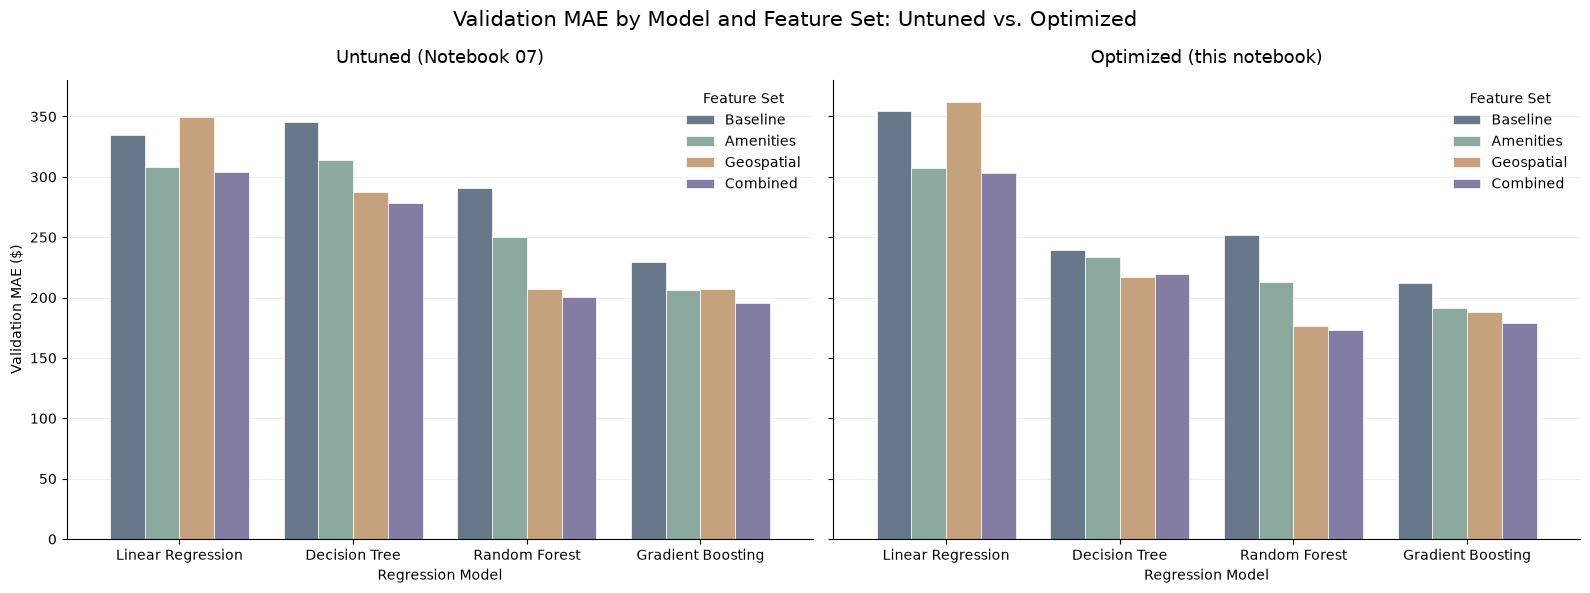

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

panels = [
    (untuned_mae, "Untuned (Notebook 07)", axes[0]),
    (optimized_mae, "Optimized (this notebook)", axes[1]),
]

for data, title, ax in panels:
    data[FEATURE_SET_ORDER].plot(
        kind="bar", ax=ax,
        color=[feature_colors[c] for c in FEATURE_SET_ORDER],
        width=0.8, edgecolor="white", linewidth=0.5
    )
    ax.set_title(title, fontsize=13, pad=12)
    ax.set_xlabel("Regression Model")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(title="Feature Set", frameon=False)

axes[0].set_ylabel("Validation MAE ($)")
fig.suptitle("Validation MAE by Model and Feature Set: Untuned vs. Optimized", fontsize=15)
plt.tight_layout()
plt.show()

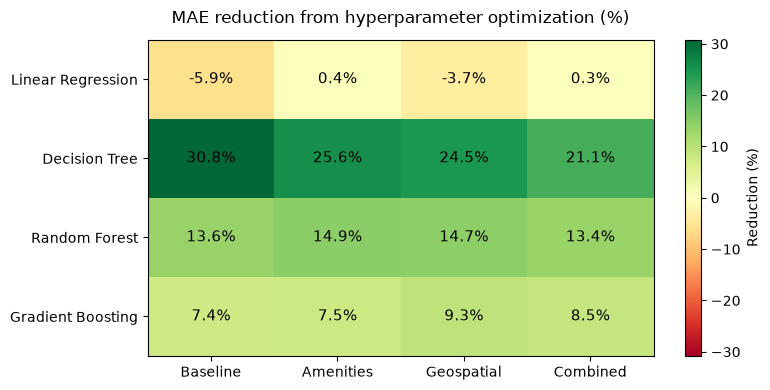

In [12]:
# Heatmap of MAE reduction from tuning (positive = tuning helped)
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(tuning_reduction.values, cmap="RdYlGn", aspect="auto",
               vmin=-abs(tuning_reduction.values).max(),
               vmax=abs(tuning_reduction.values).max())

ax.set_xticks(range(len(FEATURE_SET_ORDER)))
ax.set_xticklabels(FEATURE_SET_ORDER)
ax.set_yticks(range(len(MODEL_ORDER)))
ax.set_yticklabels(MODEL_ORDER)

for i in range(tuning_reduction.shape[0]):
    for j in range(tuning_reduction.shape[1]):
        ax.text(j, i, f"{tuning_reduction.iloc[i, j]:.1f}%",
                ha="center", va="center", fontsize=11)

ax.set_title("MAE reduction from hyperparameter optimization (%)", pad=12)
fig.colorbar(im, ax=ax, label="Reduction (%)")
plt.tight_layout()
plt.show()

## 13. Other validation metrics

For completeness, the same Model × Feature Set layout is shown for RMSE, R², and MdAPE. Lower is better for RMSE and MdAPE; higher is better for R².

In [13]:
for metric, label, better in [
    ("RMSE", "Validation RMSE ($)", "min"),
    ("R2", "Validation R²", "max"),
    ("MdAPE (%)", "Validation MdAPE (%)", "min"),
]:
    matrix = metric_matrix(validation_results, metric)
    table = matrix.copy()
    if better == "min":
        table["Best Feature Set"] = matrix.idxmin(axis=1)
        table["Best Value"] = matrix.min(axis=1)
    else:
        table["Best Feature Set"] = matrix.idxmax(axis=1)
        table["Best Value"] = matrix.max(axis=1)

    print(label)
    display(table.reset_index().round(4 if metric == "R2" else 2))
    print()

Validation RMSE ($)


Feature Set,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best Value
0,Linear Regression,570.41,518.74,582.24,511.57,Combined,511.57
1,Decision Tree,467.96,462.41,447.15,441.27,Combined,441.27
2,Random Forest,432.81,400.54,350.39,344.85,Combined,344.85
3,Gradient Boosting,385.56,356.35,357.09,341.37,Combined,341.37



Validation R²


Feature Set,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best Value
0,Linear Regression,0.6541,0.7139,0.6396,0.7218,Combined,0.7218
1,Decision Tree,0.7672,0.7727,0.7875,0.7930,Combined,0.7930
2,Random Forest,0.8009,0.8295,0.8695,0.8736,Combined,0.8736
3,Gradient Boosting,0.8420,0.8650,0.8644,0.8761,Combined,0.8761



Validation MdAPE (%)


Feature Set,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best Value
0,Linear Regression,14.70,12.29,14.61,12.27,Combined,12.27
1,Decision Tree,7.20,6.79,6.07,6.20,Geospatial,6.07
2,Random Forest,9.32,7.05,5.78,5.66,Combined,5.66
3,Gradient Boosting,7.48,6.66,6.45,6.30,Combined,6.30


## 14. Best optimized configuration

The best configuration is the (algorithm, feature set) pair with the lowest validation MAE among the 16 tuned models. This is a **model-selection result, not an unbiased estimate of generalization performance**: choosing the minimum of 16 validation scores is optimistic by construction. The test set remains untouched until the next section.

In [14]:
ranked = validation_results.sort_values("MAE").reset_index(drop=True)

print("Top 5 configurations by validation MAE:")
display(ranked.head(5).round(3))

best_row = ranked.iloc[0]
best_feature_set = best_row["Feature Set"]
best_model_name = best_row["Model"]
best_record = searches[(best_feature_set, best_model_name)]
best_model = best_record["estimator"]
best_features = feature_sets[best_feature_set]["features"]

print(f"\nBest configuration: {best_model_name} + {best_feature_set} features "
      f"({len(best_features)} predictors)")
print(f"Validation MAE:   ${best_row['MAE']:.2f}")
print(f"Validation RMSE:  ${best_row['RMSE']:.2f}")
print(f"Validation R²:    {best_row['R2']:.4f}")
print(f"Validation MdAPE: {best_row['MdAPE (%)']:.2f}%")
print(f"Cross-validation MAE (training only): ${best_record['cv_mae']:.2f}")

print("\nSelected hyperparameters:")
for name, value in best_record["best_params"].items():
    print(f"  {name}: {value}")

# Gap to the second-best configuration, to judge whether the choice is decisive
gap = ranked.loc[1, "MAE"] - ranked.loc[0, "MAE"]
print(f"\nMAE gap to runner-up ({ranked.loc[1, 'Model']} + {ranked.loc[1, 'Feature Set']}): ${gap:.2f}")

Top 5 configurations by validation MAE:


,Feature Set,Model,MAE,RMSE,R2,MdAPE (%)
0,Combined,Random Forest,173.372,344.851,0.874,5.663
1,Geospatial,Random Forest,176.824,350.389,0.869,5.778
2,Combined,Gradient Boosting,178.912,341.366,0.876,6.304
3,Geospatial,Gradient Boosting,187.934,357.086,0.864,6.451
4,Amenities,Gradient Boosting,191.086,356.354,0.865,6.664



Best configuration: Random Forest + Combined features (297 predictors)
Validation MAE:   $173.37
Validation RMSE:  $344.85
Validation R²:    0.8736
Validation MdAPE: 5.66%
Cross-validation MAE (training only): $184.11

Selected hyperparameters:
  model__max_depth: 20
  model__max_features: 0.5
  model__min_samples_leaf: 4
  model__min_samples_split: 11
  model__n_estimators: 206

MAE gap to runner-up (Random Forest + Geospatial): $3.45


## 15. Final test evaluation — run only after model selection is complete

Run this section only after the modeling decisions are finalized. It evaluates **only the selected configuration** on the held-out test set. Evaluating all 16 models on test and picking the best would turn the test set into another validation set.

Do not use these results to revise the search spaces, change the feature sets, or select a different configuration.

In [15]:
# Final, one-time evaluation of the selected configuration on the untouched test set
test_metrics = evaluate_regression(best_model, X_test_all[best_features], y_test)

print(f"Selected configuration: {best_model_name} + {best_feature_set} features")
print(f"Test MAE:   ${test_metrics['MAE']:.2f}")
print(f"Test RMSE:  ${test_metrics['RMSE']:.2f}")
print(f"Test R²:    {test_metrics['R2']:.4f}")
print(f"Test MdAPE: {test_metrics['MdAPE (%)']:.2f}%")

generalization = pd.DataFrame(
    {
        "Validation": [best_row["MAE"], best_row["RMSE"], best_row["R2"], best_row["MdAPE (%)"]],
        "Test": [test_metrics["MAE"], test_metrics["RMSE"], test_metrics["R2"], test_metrics["MdAPE (%)"]],
    },
    index=["MAE", "RMSE", "R2", "MdAPE (%)"]
)
display(generalization.round(4))

Selected configuration: Random Forest + Combined features
Test MAE:   $173.00
Test RMSE:  $321.29
Test R²:    0.8870
Test MdAPE: 5.64%


,Validation,Test
MAE,173.3719,173.0034
RMSE,344.8514,321.2917
R2,0.8736,0.8870
MdAPE (%),5.6626,5.6437


## 16. Interpretation and reporting checklist

When reporting the results, discuss:

1. **Tuning effect per model:** Which algorithms benefited most from hyperparameter optimization? Did tuning ever worsen validation MAE (negative cells in the reduction table)?
2. **Feature-set ranking after tuning:** Does the Combined set remain the best feature set for every algorithm, as it was before tuning? Did tuning change which feature set is best for any model?
3. **Interaction between tuning and features:** Does tuning narrow or widen the gaps between Baseline, Amenities, Geospatial, and Combined? Models that were weak on a feature set before tuning (e.g., Linear Regression on Geospatial) may behave differently once regularized.
4. **Best overall configuration:** Which (algorithm, feature set) pair has the lowest validation MAE, and is its margin over the runner-up practically meaningful?
5. **Consistency across metrics:** Does the best configuration also perform well on RMSE, R², and MdAPE?
6. **Validation vs. test:** How close are the validation and final test results for the selected configuration?

**Important methodological notes**
- The untuned MAEs are copied from Notebook 07 for reference; they are not recomputed in this notebook.
- Every feature set receives the same search spaces, `N_ITER`, and CV folds, so differences between columns reflect feature information rather than tuning effort.
- Linear Regression is tuned as **Ridge**, since ordinary least squares has no tunable regularization parameter. Its tuned-vs-untuned comparison therefore mixes a change of estimator with hyperparameter selection.
- With only `N_ITER` random candidates per search, a small tuned-vs-untuned difference (or a negative one) may reflect search noise, not a real effect. Increase `N_ITER` if resources allow.
- Selecting the best of 16 configurations on validation is optimistic; this is why only that single configuration is evaluated on the test set.
- Search spaces and `N_ITER` are computational choices, not guarantees of finding a global optimum.
- All preprocessing is inside the pipelines, and cross-validation is group-aware to reduce leakage between observations from the same rental unit.

## 17. Final report: untuned vs. tuned

Consolidated validation report for all 16 configurations (4 algorithms × 4 feature sets), covering **MAE, RMSE, R² and MdAPE** before and after hyperparameter optimization. Untuned values are copied from Notebook 07 and tuned values come from `validation_results` in this notebook; nothing is retrained.

- **Improv. (%):** relative improvement of the tuned model over the untuned one. Positive means tuning helped (lower MAE, RMSE and MdAPE; higher R²), negative means it got worse.
- Linear Regression compares ordinary least squares (untuned) with Ridge (tuned).

In [16]:
# Untuned validation metrics from Notebook 07 (sections 7.1, 7.3, 7.4 and 7.5).
# Copied, not recomputed here. MAE is already defined above as `untuned_mae`.
untuned_rmse = pd.DataFrame(
    {
        "Baseline":   [551.74, 533.11, 464.58, 396.24],
        "Amenities":  [518.90, 512.13, 437.19, 371.76],
        "Geospatial": [562.92, 478.83, 377.95, 371.23],
        "Combined":   [512.00, 460.30, 369.80, 361.24],
    },
    index=pd.Index(MODEL_ORDER, name="Model")
)

untuned_r2 = pd.DataFrame(
    {
        "Baseline":   [0.6764, 0.6979, 0.7706, 0.8331],
        "Amenities":  [0.7138, 0.7212, 0.7968, 0.8531],
        "Geospatial": [0.6631, 0.7563, 0.8481, 0.8535],
        "Combined":   [0.7213, 0.7748, 0.8546, 0.8613],
    },
    index=pd.Index(MODEL_ORDER, name="Model")
)

untuned_mdape = pd.DataFrame(
    {
        "Baseline":   [13.57, 14.25, 11.46, 8.52],
        "Amenities":  [12.39, 12.11,  9.00, 7.45],
        "Geospatial": [14.58, 11.63,  7.45, 7.62],
        "Combined":   [12.31, 11.11,  7.06, 7.07],
    },
    index=pd.Index(MODEL_ORDER, name="Model")
)

METRICS = {
    "MAE":       {"label": "MAE ($)",    "decimals": 2, "higher_is_better": False},
    "RMSE":      {"label": "RMSE ($)",   "decimals": 2, "higher_is_better": False},
    "R2":        {"label": "R²",         "decimals": 4, "higher_is_better": True},
    "MdAPE (%)": {"label": "MdAPE (%)",  "decimals": 2, "higher_is_better": False},
}

untuned_matrices = {
    "MAE": untuned_mae,
    "RMSE": untuned_rmse,
    "R2": untuned_r2,
    "MdAPE (%)": untuned_mdape,
}

# Tuned metrics come from `validation_results` (Section 9 of this notebook)
tuned_matrices = {metric: metric_matrix(validation_results, metric) for metric in METRICS}

In [17]:
def add_best(matrix, higher_is_better):
    table = matrix.copy()
    table["Best Feature Set"] = matrix.idxmax(axis=1) if higher_is_better else matrix.idxmin(axis=1)
    table["Best Value"] = matrix.max(axis=1) if higher_is_better else matrix.min(axis=1)
    return table

for metric, cfg in METRICS.items():
    print(f"{cfg['label']}: validation")
    for title, matrices in [("Untuned (Notebook 07)", untuned_matrices),
                            ("Tuned (this notebook)", tuned_matrices)]:
        print(f"\n{title}:")
        display(add_best(matrices[metric], cfg["higher_is_better"]).reset_index().round(cfg["decimals"]))
    print("\n" + "-" * 70 + "\n")

MAE ($): validation

Untuned (Notebook 07):


,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best Value
0,Linear Regression,334.62,308.25,349.39,304.19,Combined,304.19
1,Decision Tree,345.79,314.25,287.29,278.06,Combined,278.06
2,Random Forest,291.17,250.42,207.25,200.18,Combined,200.18
3,Gradient Boosting,229.22,206.61,207.26,195.57,Combined,195.57



Tuned (this notebook):


Feature Set,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best Value
0,Linear Regression,354.27,307.12,362.37,303.33,Combined,303.33
1,Decision Tree,239.26,233.81,216.90,219.37,Geospatial,216.90
2,Random Forest,251.59,213.22,176.82,173.37,Combined,173.37
3,Gradient Boosting,212.34,191.09,187.93,178.91,Combined,178.91



----------------------------------------------------------------------

RMSE ($): validation

Untuned (Notebook 07):


,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best Value
0,Linear Regression,551.74,518.90,562.92,512.00,Combined,512.00
1,Decision Tree,533.11,512.13,478.83,460.30,Combined,460.30
2,Random Forest,464.58,437.19,377.95,369.80,Combined,369.80
3,Gradient Boosting,396.24,371.76,371.23,361.24,Combined,361.24


... (7 outputs left out)

,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best Value
0,Linear Regression,13.57,12.39,14.58,12.31,Combined,12.31
1,Decision Tree,14.25,12.11,11.63,11.11,Combined,11.11
2,Random Forest,11.46,9.00,7.45,7.06,Combined,7.06
3,Gradient Boosting,8.52,7.45,7.62,7.07,Combined,7.07



Tuned (this notebook):


Feature Set,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best Value
0,Linear Regression,14.70,12.29,14.61,12.27,Combined,12.27
1,Decision Tree,7.20,6.79,6.07,6.20,Geospatial,6.07
2,Random Forest,9.32,7.05,5.78,5.66,Combined,5.66
3,Gradient Boosting,7.48,6.66,6.45,6.30,Combined,6.30



----------------------------------------------------------------------



In [18]:
# Summary table: every model x feature set, every metric, untuned vs. tuned
index = pd.MultiIndex.from_product([MODEL_ORDER, FEATURE_SET_ORDER], names=["Model", "Feature Set"])
columns = pd.MultiIndex.from_tuples(
    [(cfg["label"], kind) for cfg in METRICS.values() for kind in ["Untuned", "Tuned", "Improv. (%)"]]
)
final_report = pd.DataFrame(index=index, columns=columns, dtype=float)

for model, fs in index:
    for metric, cfg in METRICS.items():
        untuned_value = untuned_matrices[metric].loc[model, fs]
        tuned_value = tuned_matrices[metric].loc[model, fs]
        change = (tuned_value - untuned_value) if cfg["higher_is_better"] else (untuned_value - tuned_value)

        final_report.loc[(model, fs), (cfg["label"], "Untuned")] = untuned_value
        final_report.loc[(model, fs), (cfg["label"], "Tuned")] = tuned_value
        final_report.loc[(model, fs), (cfg["label"], "Improv. (%)")] = change / untuned_value * 100

for metric, cfg in METRICS.items():
    label = cfg["label"]
    for kind in ["Untuned", "Tuned"]:
        final_report[(label, kind)] = final_report[(label, kind)].round(cfg["decimals"])
    final_report[(label, "Improv. (%)")] = final_report[(label, "Improv. (%)")].round(2)

with pd.option_context("display.max_columns", None, "display.width", 250):
    display(final_report)

MAE ($)                     RMSE ($)                          R²                     MdAPE (%)                   
                              Untuned   Tuned Improv. (%)  Untuned   Tuned Improv. (%) Untuned   Tuned Improv. (%)   Untuned  Tuned Improv. (%)
Model             Feature Set                                                                                                                  
Linear Regression Baseline     334.62  354.27       -5.87   551.74  570.41       -3.38  0.6764  0.6541       -3.29     13.57  14.70       -8.34
                  Amenities    308.25  307.12        0.37   518.90  518.74        0.03  0.7138  0.7139        0.02     12.39  12.29        0.80
                  Geospatial   349.39  362.37       -3.71   562.92  582.24       -3.43  0.6631  0.6396       -3.54     14.58  14.61       -0.18
                  Combined     304.19  303.33        0.28   512.00  511.57        0.08  0.7213  0.7218        0.07     12.31  12.27        0.34
Decision Tree     Baseline     345.79  239.26       30.81   533.11  467.96       12.22  0.6979  0.7672        9.93     14.25   7.20       49.47
                  Amenities    314.25  233.81       25.60   512.13  462.41        9.71  0.7212  0.7727        7.14     12.11   6.79       43.94
                  Geospatial   287.29  216.90       24.50   478.83  447.15        6.62  0.7563  0.7875        4.12     11.63   6.07       47.81
                  Combined     278.06  219.37       21.11   460.30  441.27        4.13  0.7748  0.7930        2.35     11.11   6.20       44.24
Random Forest     Baseline     291.17  251.59       13.59   464.58  432.81        6.84  0.7706  0.8009        3.93     11.46   9.32       18.72
                  Amenities    250.42  213.22       14.86   437.19  400.54        8.38  0.7968  0.8295        4.10      9.00   7.05       21.65
                  Geospatial   207.25  176.82       14.68   377.95  350.39        7.29  0.8481  0.8695        2.52      7.45   5.78       22.44
                  Combined     200.18  173.37       13.39   369.80  344.85        6.75  0.8546  0.8736        2.22      7.06   5.66       19.79
Gradient Boosting Baseline     229.22  212.34        7.36   396.24  385.56        2.70  0.8331  0.8420        1.06      8.52   7.48       12.15
                  Amenities    206.61  191.09        7.51   371.76  356.35        4.14  0.8531  0.8650        1.40      7.45   6.66       10.55
                  Geospatial   207.26  187.93        9.32   371.23  357.09        3.81  0.8535  0.8644        1.28      7.62   6.45       15.34
                  Combined     195.57  178.91        8.52   361.24  341.37        5.50  0.8613  0.8761        1.72      7.07   6.30       10.83